# التحليل الاستكشافي وتنظيف البيانات — أولويات الدعم

**سؤال الجمعية:** أي الأسر نبدأ بدعمها هذا الشهر بميزانية محدودة؟ وأي الأسر نصل إليها **وقائيًا** قبل أن تقع في أزمة (انقطاع خدمة، إخلاء، تعثّر في السداد)؟

**القرار الذي يدعمه التحليل:** ترتيب الأسر في ثلاث أولويات (عالية / متوسطة / منخفضة)، مع درجتين قابلتين للتفسير: **الحاجة الآن** و**مخاطر الأزمة القريبة**، ثم توزيع الميزانية على هذا الترتيب. القرار النهائي للمسؤول عن التوزيع.

**محتوى الدفتر:**
1. تنظيف ملف Excel حقيقي الشكل (أخطاء الإدخال الشائعة) وتوثيق كل خطوة.
2. سلامة البيانات التجريبية ومعايرتها على الأرقام السعودية.
3. ما الذي يميّز الأسر عالية الأولوية؟
4. اختيار الميزات للنموذج.
5. خريطة الأولوية: من نحتاج للوصول إليه وقائيًا؟

> ⚠️ البيانات **تجريبية** مضبوطة على إحصاءات سعودية منشورة (انظر `data/README.md`). النتائج تصف منطق التوليد، وليست حقائق عن أسر حقيقية.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from model.plotting import setup, PRIORITY_COLORS, PRIORITY_AR, ORDER, INK2, NEED, RISK, PREVENT
from model.features import add_engineered, encode, SELECTED, FEATURE_LABELS_AR, SAUDI_PER_CAPITA_INCOME, SAMA_DEBT_BURDEN_CAP
from model.scoring import need_score, risk_score
from model.cleaning import clean_frame
from model.schema import FIELD_BY_NAME
setup()
FIG = '../docs/figures/'
def save(fig, name): fig.savefig(FIG + name); plt.show()
pd.set_option('display.max_colwidth', 80)

## 1. تنظيف البيانات: ملف Excel كما تعبّئه الجمعيات فعلًا

الملف `data/samples/sample_messy.xlsx` بنفس قالب الموقع، لكن فيه أخطاء الإدخال الشائعة: أرقام هندية، و«ريال» داخل الخانة، وفواصل آلاف، واختلاف إملائي (ايجار/إيجار)، ومرادفات (راتب = ثابت)، وخانات فارغة، وصف فارغ، ورمز مكرر، وقيم مستحيلة.

خط التنظيف (`model/cleaning.py`) هو نفسه الذي يعمل في الموقع عند رفع الملف:

| الخطوة | ماذا تفعل | الإجراء |
|---|---|---|
| مطابقة الأعمدة | تقبل العناوين العربية والمرادفات (الدخل، الإيجار، الديون…) | الأعمدة المطلوبة الناقصة ← رفض الملف برسالة واضحة |
| توحيد النص | توحيد الألف والتاء المربوطة والياء، وحذف التشكيل والرموز ✓ | — |
| الأرقام | تحويل ٠-٩ إلى 0-9، وحذف «ريال» والفواصل | **تصحيح** يُسجَّل |
| القيم الفئوية | مطابقة المرادفات مع القيم المعتمدة | **تصحيح** يُسجَّل، أو **رفض** إن كانت مجهولة |
| الخانات الاختيارية الفارغة | الفواتير والديون والطلاب ← صفر | **تصحيح** يُسجَّل |
| قواعد المنطق | مجموع الطلاب < عدد الأفراد، إيجار للمستأجر، قسط ≤ الدين | **رفض** الصف مع السبب |
| التكرار | الرمز المكرر يُحذف (يبقى الأول) | **رفض** يُسجَّل |
| القيم الشاذة | دخل > 60,000 أو دين > مليون… | تُقبل وتُعلَّم **للتحقق** |
| الصفوف الفارغة | تُتجاهل | تُعدّ في التقرير |

In [2]:
raw = pd.read_excel('../data/samples/sample_messy.xlsx', sheet_name='الأسر', dtype=str)
result = clean_frame(raw)
pd.Series(result['summary']).to_frame('العدد')

,العدد
rows_read,29
blank_rows_skipped,1
accepted,25
accepted_with_fixes,9
rejected,4
flagged_for_review,1
unknown_columns,[]


In [3]:
issues = pd.DataFrame(result['issues'])
issues['العمود'] = issues.field.map(lambda f: FIELD_BY_NAME[f].label if f in FIELD_BY_NAME else f)
issues.rename(columns={'row': 'الصف', 'value': 'القيمة في الملف', 'action': 'الإجراء', 'message': 'التفصيل'})[['الصف', 'العمود', 'القيمة في الملف', 'الإجراء', 'التفصيل']]

,الصف,العمود,القيمة في الملف,الإجراء,التفصيل
0,2,الدخل الشهري,٤٤١٠ ريال,fixed,"حُوّلت إلى الرقم 4,410"
1,3,المصروفات المعيشية,"6,140",fixed,"حُوّلت إلى الرقم 6,140"
2,4,الحالة السكنية,ايجار,fixed,وُحّدت إلى «إيجار»
3,5,حالة صحية مزمنة أو إعاقة,نعم ✓,fixed,وُحّدت إلى «نعم»
4,6,مصدر الدخل,راتب,fixed,وُحّدت إلى «ثابت»
5,7,فواتير الخدمات الشهرية,,fixed,خانة فارغة اعتُبرت صفرًا
6,8,الكهرباء,مفصول احيانا,fixed,وُحّدت إلى «متقطع»
7,9,رمز الأسرة,R-1007,rejected,الرمز مكرر (ورد أولًا في الصف 8). حُذف الصف المكرر.
8,10,طلاب المرحلة الابتدائية,3,rejected,مجموع الطلاب يجب أن يكون أقل من عدد أفراد الأسرة.
9,11,الدخل الشهري,غير معروف,rejected,«غير معروف» ليس رقمًا.


**النتيجة:** من 29 صفًا مقروءًا قُبل 25 صفًا، منها 9 صُحّحت تلقائيًا، ورُفضت 4 صفوف بسبب واضح لكل منها، وعُلّم صف واحد للتحقق اليدوي، وتُجوهل صف فارغ. لا يُحذف أي شيء بصمت: كل تغيير يظهر للمستخدم في «تقرير التنظيف» داخل الموقع.

## 2. البيانات التجريبية: السلامة والمعايرة

In [4]:
df = pd.read_csv('../data/raw/synthetic_households.csv')
fe = add_engineered(df)
fe['need'], fe['risk'] = need_score(df), risk_score(df)
print(df.shape)
checks = {
    'قيم مفقودة': int(df.isna().sum().sum()),
    'رموز مكررة': int(df.household_id.duplicated().sum()),
    'طلاب ≥ عدد الأفراد': int((fe.students >= fe.household_size).sum()),
    'دخل سالب': int((df.monthly_income < 0).sum()),
    'إيجار لغير المستأجر': int(((df.monthly_rent > 0) & (df.housing_status != 'rented')).sum()),
    'قسط بدون دين': int(((df.monthly_debt_payment > 0) & (df.total_debt <= 0)).sum()),
}
pd.Series(checks, name='مخالفات').to_frame()

(3000, 20)


,مخالفات
قيم مفقودة,0
رموز مكررة,0
طلاب ≥ عدد الأفراد,0
دخل سالب,0
إيجار لغير المستأجر,0
قسط بدون دين,0


In [5]:
ref = pd.DataFrame({
    'المتقدّمون للجمعية (تجريبي)': [df.household_size.mean(), df.monthly_income.mean(), fe.per_capita_income.mean(),
                                    (df.housing_status == 'owned').mean() * 100, fe.has_debt.mean() * 100],
    'الأسرة السعودية': [4.8, 13655, SAUDI_PER_CAPITA_INCOME, 65.4, np.nan],
    'المصدر': ['تعداد 2022', 'الوسيط — مسح الدخل والإنفاق 2023', 'الوسيط — مسح الدخل والإنفاق 2023', 'برنامج الإسكان 2024', '—'],
}, index=['حجم الأسرة', 'دخل الأسرة (ريال)', 'دخل الفرد (ريال)', 'تملّك المسكن %', 'أسر عليها دين %'])
ref.round(1)

,المتقدّمون للجمعية (تجريبي),الأسرة السعودية,المصدر
حجم الأسرة,5.2,4.8,تعداد 2022
دخل الأسرة (ريال),5166.7,13655.0,الوسيط — مسح الدخل والإنفاق 2023
دخل الفرد (ريال),1252.4,2896.0,الوسيط — مسح الدخل والإنفاق 2023
تملّك المسكن %,39.0,65.4,برنامج الإسكان 2024
أسر عليها دين %,54.6,NaN,—


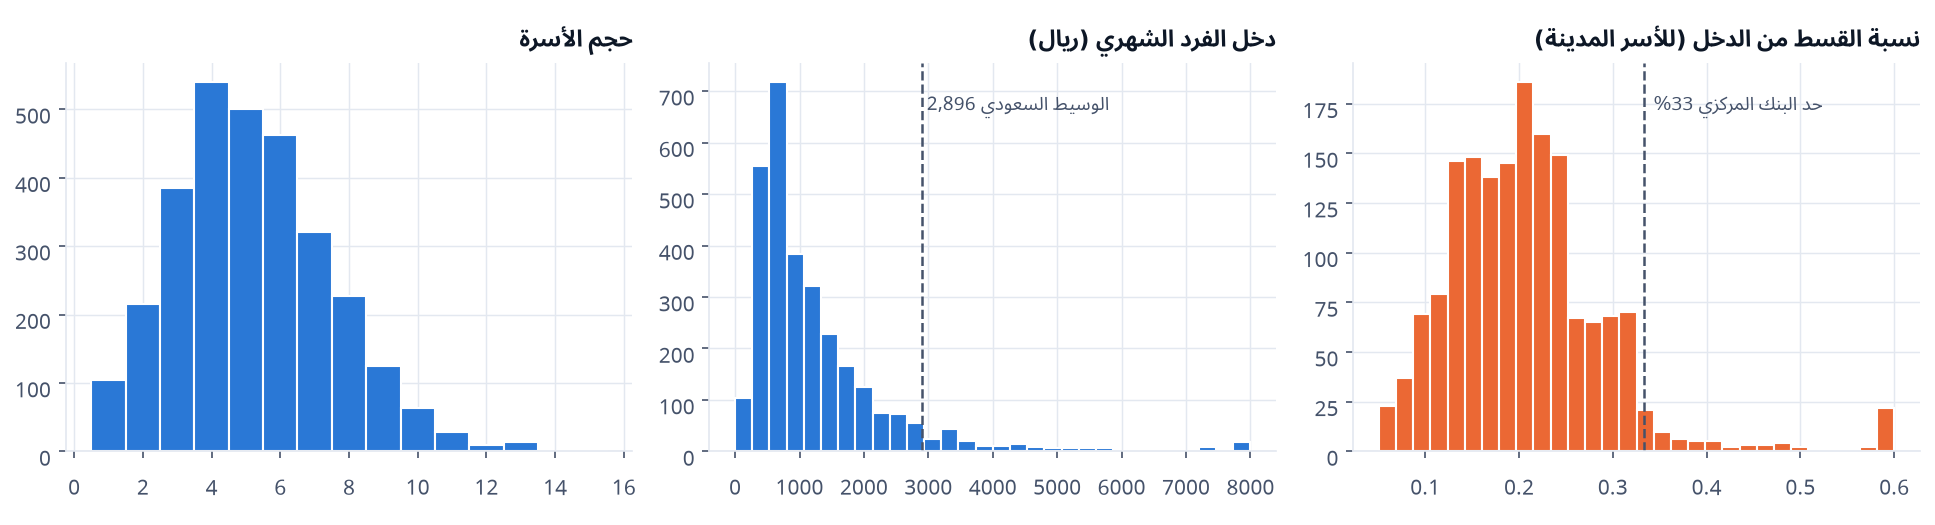

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(df.household_size, bins=np.arange(0.5, df.household_size.max() + 1.5), color=NEED, edgecolor='white')
axes[0].set_title('حجم الأسرة', loc='right')
axes[1].hist(fe.per_capita_income.clip(upper=8000), bins=30, color=NEED, edgecolor='white')
axes[1].axvline(SAUDI_PER_CAPITA_INCOME, color=INK2, ls='--', lw=1.2)
axes[1].text(SAUDI_PER_CAPITA_INCOME + 80, axes[1].get_ylim()[1] * .88, 'الوسيط السعودي 2,896', color=INK2, fontsize=9)
axes[1].set_title('دخل الفرد الشهري (ريال)', loc='right')
d = fe.debt_service_ratio[fe.has_debt == 1].clip(upper=.6)
axes[2].hist(d, bins=30, color=RISK, edgecolor='white')
axes[2].axvline(SAMA_DEBT_BURDEN_CAP, color=INK2, ls='--', lw=1.2)
axes[2].text(SAMA_DEBT_BURDEN_CAP + .01, axes[2].get_ylim()[1] * .88, 'حد البنك المركزي 33%', color=INK2, fontsize=9)
axes[2].set_title('نسبة القسط من الدخل (للأسر المدينة)', loc='right')
fig.tight_layout(); save(fig, 'eda_distributions.png')

المتقدّمون أسرهم أكبر قليلًا، ودخل الفرد أقل بوضوح من الوسيط السعودي، والتملّك أقل — وهذا مقصود لأن البيانات تمثّل من يطرق باب الجمعية. نحو نصف الأسر عليها ديون، وقسط بعضها يقترب من الحد النظامي 33%.

## 3. ما الذي يميّز الأسر عالية الأولوية؟

In [7]:
counts = df.priority_label.value_counts().reindex(ORDER)
pd.DataFrame({'العدد': counts.values, 'النسبة': (counts / len(df)).round(3).values}, index=[PRIORITY_AR[k] for k in ORDER])

,العدد,النسبة
عالية,750,0.25
متوسطة,1200,0.40
منخفضة,1050,0.35


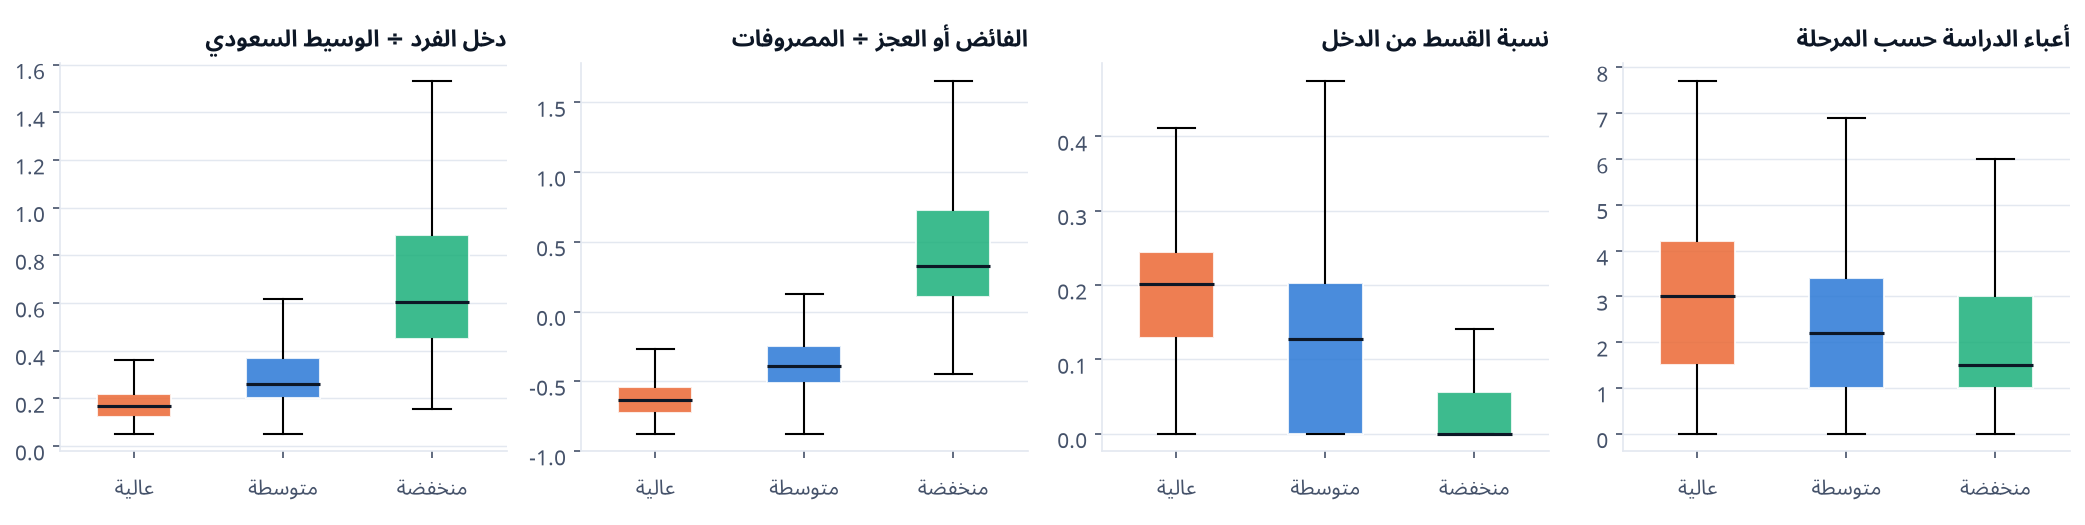

,income_to_saudi_avg,surplus_ratio,debt_service_ratio,education_load
priority_label,,,,
عالية,0.17,-0.63,0.20,3.0
متوسطة,0.26,-0.39,0.13,2.2
منخفضة,0.60,0.32,0.00,1.5


In [8]:
cols = [('income_to_saudi_avg', 'دخل الفرد ÷ الوسيط السعودي'), ('surplus_ratio', 'الفائض أو العجز ÷ المصروفات'),
        ('debt_service_ratio', 'نسبة القسط من الدخل'), ('education_load', 'أعباء الدراسة حسب المرحلة')]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (col, title) in zip(axes, cols):
    data = [fe.loc[fe.priority_label == k, col].clip(fe[col].quantile(.01), fe[col].quantile(.99)) for k in ORDER]
    bp = ax.boxplot(data, tick_labels=[PRIORITY_AR[k] for k in ORDER], patch_artist=True, widths=.5, showfliers=False,
                    medianprops={'color': '#0d1726', 'lw': 1.5})
    for patch, k in zip(bp['boxes'], ORDER):
        patch.set(facecolor=PRIORITY_COLORS[k], alpha=.85, edgecolor='white')
    ax.set_title(title, loc='right'); ax.grid(axis='x', visible=False)
fig.tight_layout(); save(fig, 'eda_by_priority.png')
fe.groupby('priority_label')[[c for c, _ in cols]].median().reindex(ORDER).rename(index=PRIORITY_AR).round(2)

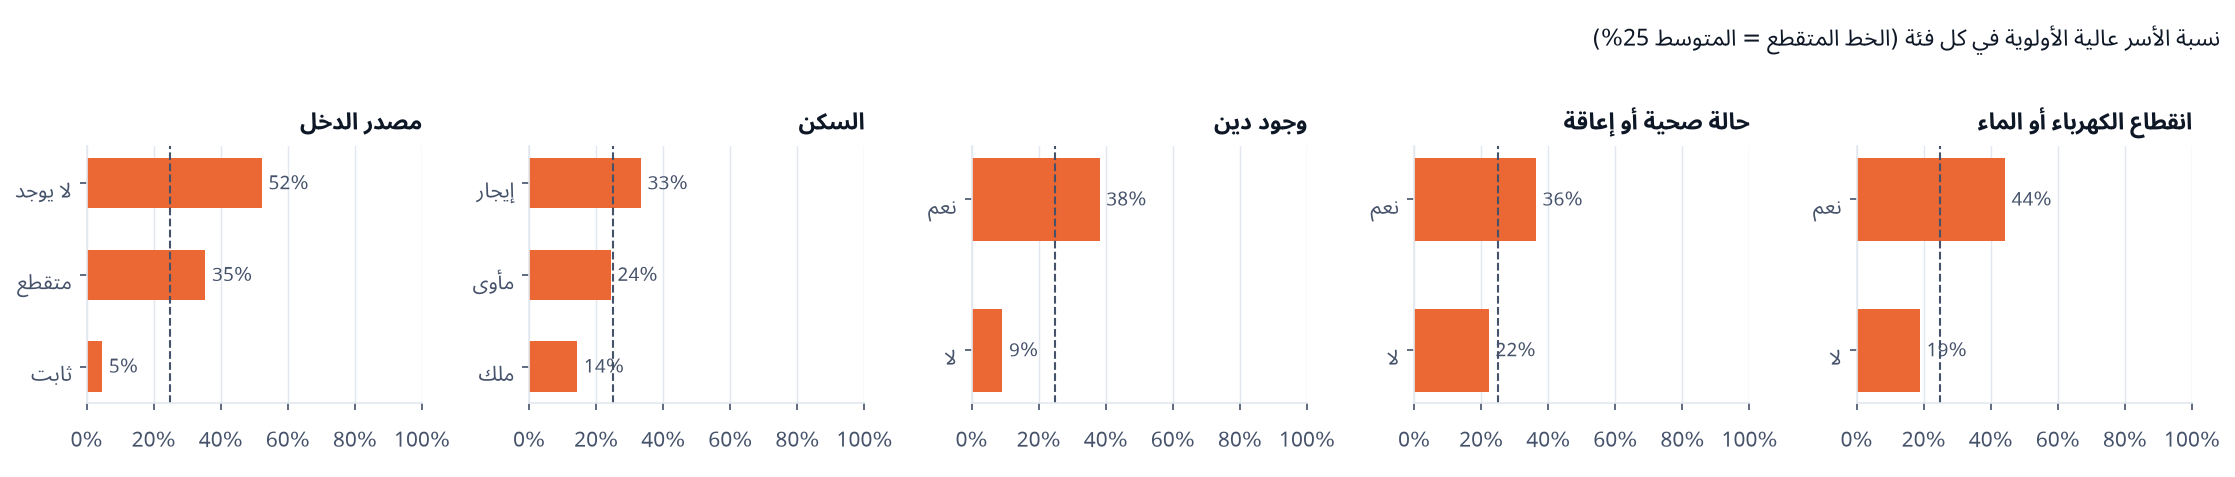

In [9]:
cat = {'income_source': 'مصدر الدخل', 'housing_status': 'السكن', 'has_debt': 'وجود دين',
       'has_health_or_disability': 'حالة صحية أو إعاقة', 'cutoff_warning': 'انقطاع الكهرباء أو الماء'}
labels = {'income_source': {'stable': 'ثابت', 'irregular': 'متقطع', 'none': 'لا يوجد'},
          'housing_status': {'owned': 'ملك', 'rented': 'إيجار', 'shelter': 'مأوى'},
          'has_debt': {0: 'لا', 1: 'نعم'}, 'has_health_or_disability': {'no': 'لا', 'yes': 'نعم'}, 'cutoff_warning': {0: 'لا', 1: 'نعم'}}
overall = (fe.priority_label == 'high').mean()
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, (col, title) in zip(axes, cat.items()):
    share = fe.groupby(col).priority_label.apply(lambda s: (s == 'high').mean()).sort_values()
    ax.barh([labels[col][v] for v in share.index], share.values, color=PRIORITY_COLORS['high'], height=.55)
    ax.axvline(overall, color=INK2, ls='--', lw=1)
    for i, v in enumerate(share.values): ax.text(v + .02, i, f'{v:.0%}', va='center', fontsize=9, color=INK2)
    ax.set_xlim(0, 1); ax.set_title(title, loc='right'); ax.grid(axis='y', visible=False)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
fig.suptitle(f'نسبة الأسر عالية الأولوية في كل فئة (الخط المتقطع = المتوسط {overall:.0%})', x=.99, ha='right', fontsize=11)
fig.tight_layout(); save(fig, 'eda_categorical.png')

## 4. اختيار الميزات

نقيس قوة علاقة كل ميزة مرشّحة بالأولوية بطريقتين: **Mutual Information** (تلتقط العلاقات غير الخطية) و**Spearman** (اتجاه العلاقة)، ثم نستبعد الميزات المكررة (ارتباط > 0.8).

In [10]:
candidates = ['household_size', 'monthly_income', 'total_expenses', 'per_capita_income', 'income_to_saudi_avg', 'surplus_ratio',
              'housing_cost_burden', 'debt_service_ratio', 'debt_to_annual_income', 'total_debt', 'education_load', 'students',
              'income_source', 'housing_status', 'has_health_or_disability', 'cutoff_warning', 'electricity_access',
              'water_access', 'internet_access']
X = encode(fe)[candidates]
y = fe.priority_label.map({'low': 0, 'medium': 1, 'high': 2})
mi = pd.Series(mutual_info_classif(X, y, random_state=42), index=candidates)
rho = X.apply(lambda c: c.corr(y, method='spearman'))
scores = pd.DataFrame({'mutual_info': mi, 'spearman': rho, 'مختارة': [c in SELECTED for c in candidates]}).sort_values('mutual_info', ascending=False)
scores.round(3)

,mutual_info,spearman,مختارة
surplus_ratio,0.593,-0.850,True
income_to_saudi_avg,0.426,-0.772,True
per_capita_income,0.422,-0.772,False
monthly_income,0.331,-0.705,False
housing_cost_burden,0.295,0.660,True
income_source,0.221,0.605,True
total_debt,0.163,0.314,False
debt_service_ratio,0.138,0.450,True
debt_to_annual_income,0.102,0.451,True
total_expenses,0.073,0.335,False


In [11]:
corr = X.corr(method='spearman').abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
pairs[pairs > .8].round(2).to_frame('الارتباط')

,,الارتباط
per_capita_income,income_to_saudi_avg,1.00
education_load,students,0.97
debt_to_annual_income,total_debt,0.94
debt_service_ratio,debt_to_annual_income,0.93
income_to_saudi_avg,surplus_ratio,0.90
per_capita_income,surplus_ratio,0.90
debt_service_ratio,total_debt,0.89
monthly_income,surplus_ratio,0.86


**الميزات المختارة (12):** نختار من كل مجموعة مكررة الميزة الأوضح تفسيرًا، ونُبقي ميزات المخاطر حتى لو كانت علاقتها أضعف لأنها جوهر الهدف الوقائي.

| المجموعة | المختارة | المستبعدة ولماذا |
|---|---|---|
| الدخل | `income_to_saudi_avg` | `monthly_income`, `per_capita_income`: نفس المعلومة، والنسبة للوسيط السعودي أوضح |
| التوازن المالي | `surplus_ratio` | `total_expenses`: مضمّنة في النسبة |
| السكن | `housing_status`, `housing_cost_burden` | — |
| الدين | `debt_service_ratio`, `debt_to_annual_income` | `total_debt`: مبلغ خام، والنسبة للدخل أعدل بين الأسر |
| الدراسة | `education_load` | `students`: لا يفرّق بين الابتدائي والجامعة |
| الخدمات | `cutoff_warning`, `internet_access` | الكهرباء والماء منفصلين: مدمجان في إنذار الانقطاع لأن الانقطاع الكامل نادر |
| أخرى | `income_source`, `has_health_or_disability`, `household_size` | — |

## 5. خريطة الأولوية: الحاجة الآن مقابل مخاطر الأزمة القريبة

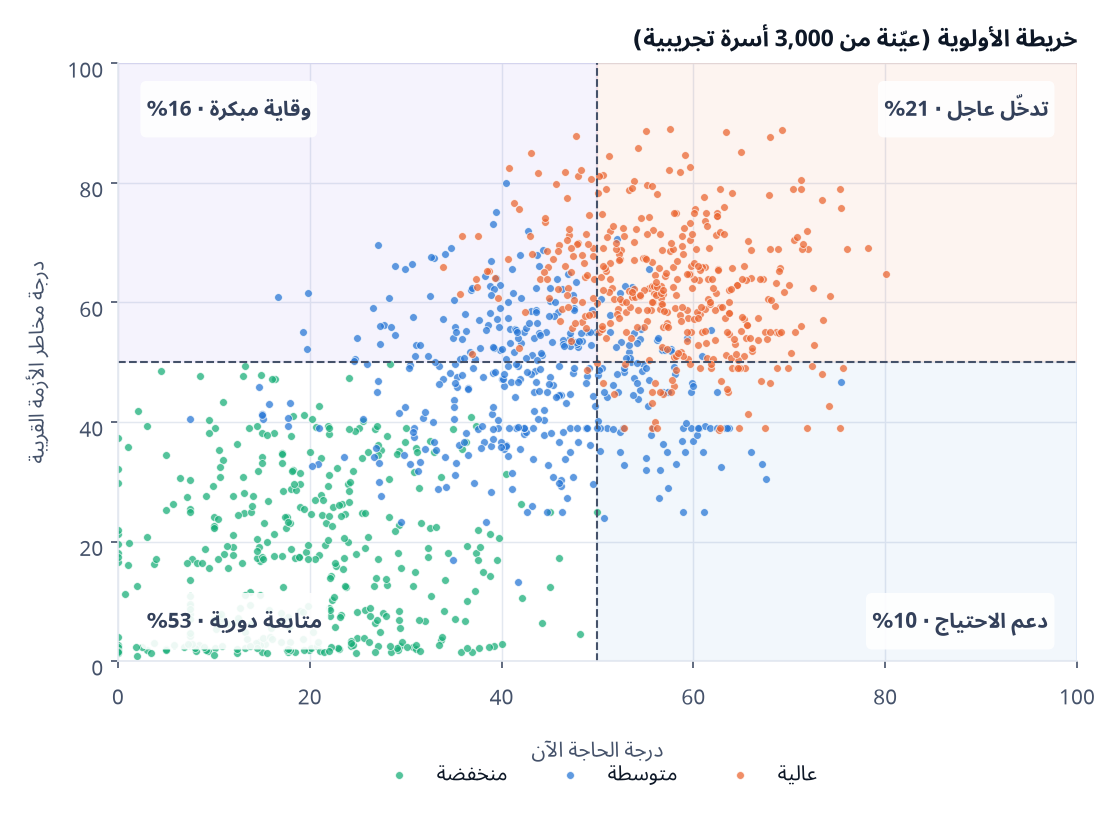

أسر الوقاية المبكرة: 484 (16%). منها 99% أولويتها متوسطة أو عالية رغم أن حاجتها الحالية أقل من 50.


In [12]:
fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.axhspan(50, 100, xmin=0, xmax=.5, color=PREVENT, alpha=.07); ax.axhspan(50, 100, xmin=.5, xmax=1, color=RISK, alpha=.07)
ax.axhspan(0, 50, xmin=.5, xmax=1, color=NEED, alpha=.06)
for k in ['low', 'medium', 'high']:
    s = fe[fe.priority_label == k].sample(min(400, (fe.priority_label == k).sum()), random_state=1)
    ax.scatter(s.need, s.risk, s=14, color=PRIORITY_COLORS[k], alpha=.75, edgecolor='white', linewidth=.4, label=PRIORITY_AR[k])
ax.axvline(50, color=INK2, ls='--', lw=1); ax.axhline(50, color=INK2, ls='--', lw=1)
quad = {'وقاية مبكرة': (fe.need < 50) & (fe.risk >= 50), 'تدخّل عاجل': (fe.need >= 50) & (fe.risk >= 50),
        'متابعة دورية': (fe.need < 50) & (fe.risk < 50), 'دعم الاحتياج': (fe.need >= 50) & (fe.risk < 50)}
for (name, mask), (x, y_, ha) in zip(quad.items(), [(3, 96, 'left'), (97, 96, 'right'), (3, 3, 'left'), (97, 3, 'right')]):
    ax.text(x, y_, f'{name} · {mask.mean():.0%}', ha=ha, va='top' if y_ > 50 else 'bottom', fontsize=10, fontweight='bold', color='#33405a',
            bbox=dict(boxstyle='round,pad=.3', fc='white', ec='none', alpha=.9), zorder=5)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel('درجة الحاجة الآن'); ax.set_ylabel('درجة مخاطر الأزمة القريبة')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(.5, -.12), ncol=3); ax.set_title('خريطة الأولوية (عيّنة من 3,000 أسرة تجريبية)', loc='right')
fig.tight_layout(); save(fig, 'eda_priority_map.png')
prevent = fe[quad['وقاية مبكرة']]
print(f"أسر الوقاية المبكرة: {len(prevent)} ({len(prevent)/len(fe):.0%}). منها {(prevent.priority_label != 'low').mean():.0%} أولويتها متوسطة أو عالية رغم أن حاجتها الحالية أقل من 50.")

## 6. الخلاصة

1. **التنظيف:** خط تنظيف موحّد وموثّق يحوّل ملفات الجمعيات الفعلية إلى بيانات صالحة، ويُظهر كل تصحيح ورفض للمستخدم.
2. **المعايرة:** البيانات تشبه المتقدّمين للجمعيات السعودية: دخل الفرد نحو نصف المتوسط الوطني، ونصف الأسر تقريبًا مدين.
3. **ما يرفع الأولوية:** العجز الشهري، وانخفاض دخل الفرد، وعدم ثبات الدخل، وثقل القسط، والإيجار والفواتير المرتفعة.
4. **القيمة الوقائية:** نحو 16% من الأسر في مربع «الوقاية المبكرة»: حاجتها الحالية أقل من 50 لكن مخاطرها مرتفعة، و99% منها حصلت على أولوية متوسطة أو عالية. الطريقة التقليدية (الحاجة فقط) كانت ستؤخّر هذه الأسر.
5. **قيد منهجي:** الوسوم مشتقة من معادلة الدرجات، فالنموذج سيبدو دقيقًا على هذه البيانات. الدقة الحقيقية تُقاس فقط بمقارنته بقرارات الجمعية (انظر التقرير، قسم التحقق).